# Clustering Notebook

## Data And Libraries Import 

In [1]:
import pandas as pd
import numpy as np


import matplotlib.pyplot as plt
import seaborn as sns


import os
from dotenv import load_dotenv
from pathlib import Path

from sqlalchemy import create_engine, text

import warnings
warnings.filterwarnings('ignore')

In [2]:
env_path = Path.cwd()/"github_repo_cloned"/"festival_restocking_problem"/".env"
load_dotenv(env_path)


host = os.getenv("DB_HOST")
user = os.getenv("DB_USER")
port = os.getenv("DB_PORT")
password = os.getenv("DB_PASSword")
db = os.getenv("DB_NAME")

In [3]:
engine = create_engine(f"mysql+pymysql://{user}:{password}@{host}:{port}/{db}")

def sql(query, engine = engine):
    with engine.connect() as conn:
        df = pd.read_sql(text(query),conn)
    return df

In [4]:
out_path = os.path.join(os.getenv("OUTPUT_DIR"), "lead_table.csv")
data = pd.read_csv(out_path)

In [5]:
data.head()

,festival,Andhra Pradesh,Assam,Bihar,Delhi,Gujarat,Karnataka,Kerala,Maharashtra,Odisha,Punjab,Rajasthan,Tamil Nadu,Telangana,Uttar Pradesh,West Bengal
0,Bihu (Rongali),0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.5,0.0,0.0
1,Christmas,5.0,5.0,4.0,5.0,5.0,6.5,6.0,5.5,3.0,5.0,4.5,6.0,6.0,4.0,5.0
2,Diwali,8.0,6.5,8.0,10.5,10.0,9.5,6.0,7.5,4.0,10.0,10.0,10.0,8.5,9.5,6.0
3,Durga Puja/Navratri,4.0,10.0,7.5,3.0,7.5,5.5,3.0,4.0,7.0,3.0,4.5,4.5,5.5,2.5,9.0
4,Eid al-Fitr,1.0,1.5,3.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.5,2.0,3.0


In [7]:
data.shape

(10, 16)

## Analysis

In [8]:
states = data.set_index('festival').T
states.shape

(15, 10)

In [9]:
states

festival,Bihu (Rongali),Christmas,Diwali,Durga Puja/Navratri,Eid al-Fitr,Ganesh Chaturthi,Holi,Onam,Pongal,Raksha Bandhan
Andhra Pradesh,0.0,5.0,8.0,4.0,1.0,7.5,3.0,5.0,4.0,6.0
Assam,1.0,5.0,6.5,10.0,1.5,4.5,6.5,4.0,1.0,5.0
Bihar,0.0,4.0,8.0,7.5,3.0,3.0,7.5,2.5,2.0,6.0
Delhi,0.0,5.0,10.5,3.0,2.0,5.5,10.0,6.0,2.0,9.0
Gujarat,0.0,5.0,10.0,7.5,1.0,6.5,9.5,5.0,3.5,8.0
Karnataka,0.0,6.5,9.5,5.5,1.0,7.0,6.5,7.5,4.0,7.5
Kerala,0.0,6.0,6.0,3.0,1.0,2.5,2.0,7.0,4.5,4.0
Maharashtra,0.0,5.5,7.5,4.0,1.0,7.0,8.0,4.5,3.0,7.0
Odisha,0.0,3.0,4.0,7.0,1.0,6.0,5.0,3.5,2.5,6.5
Punjab,0.0,5.0,10.0,3.0,1.0,3.0,8.5,3.0,3.0,9.0


In [10]:
states = states.drop(columns=['Bihu (Rongali)', 'Eid al-Fitr'])

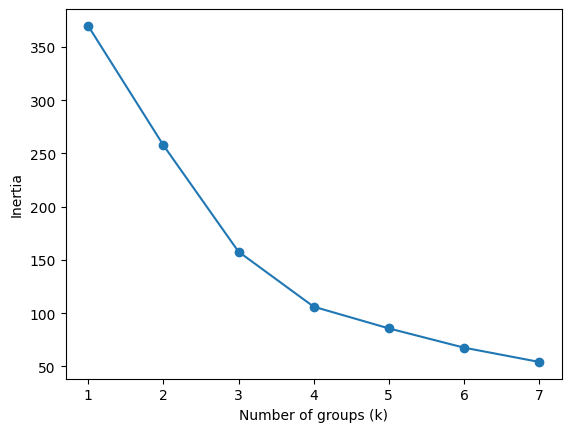

In [12]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertia = []
ks = range(1, 8)
for k in ks:
    inertia.append(KMeans(n_clusters=k, n_init=10, random_state=42).fit(states).inertia_)

plt.plot(ks, inertia, marker='o')
plt.xlabel('Number of groups (k)')
plt.ylabel('Inertia')
plt.show()

In [14]:
km = KMeans(n_clusters=4, n_init=10, random_state=42).fit(states)
states['group'] = km.labels_
states.sort_values('group')['group']

Andhra Pradesh    0
Kerala            0
Tamil Nadu        0
Delhi             1
Uttar Pradesh     1
Rajasthan         1
Punjab            1
Assam             2
Odisha            2
West Bengal       2
Bihar             2
Gujarat           3
Maharashtra       3
Karnataka         3
Telangana         3
Name: group, dtype: int32

In [15]:
states.groupby('group').mean().round(1)

festival,Christmas,Diwali,Durga Puja/Navratri,Ganesh Chaturthi,Holi,Onam,Pongal,Raksha Bandhan
group,,,,,,,,
0,5.7,8.0,3.8,5.0,2.2,6.2,3.8,5.2
1,4.6,10.0,3.2,3.9,9.1,4.0,2.5,8.2
2,4.2,6.1,8.4,4.4,6.5,3.2,1.9,6.0
3,5.8,8.9,5.6,7.2,7.6,5.5,3.5,7.4


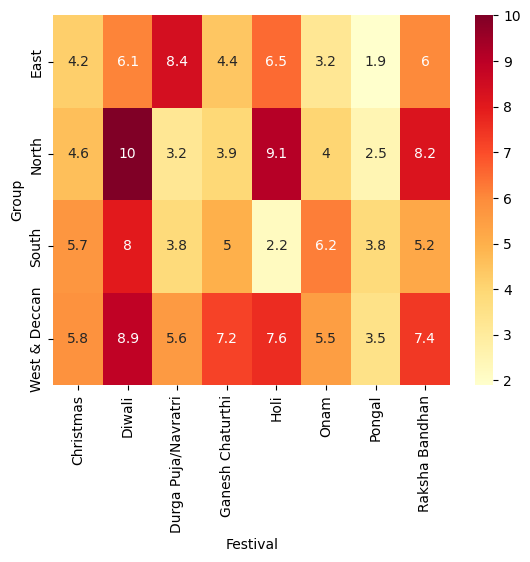

In [17]:
group_names = {0: 'South', 1: 'North', 2: 'East', 3: 'West & Deccan'}

states['group_name'] = states['group'].map(group_names)

group_mean = states.drop(columns='group').groupby('group_name').mean().round(1)

sns.heatmap(group_mean, annot=True, cmap='YlOrRd')
plt.xlabel('Festival')
plt.ylabel('Group')
plt.show()

In [18]:
states[['group_name']].to_csv(os.path.join(os.getenv("OUTPUT_DIR"), "state_groups.csv"))